# Joystick Control
As the first step after successfully communicating with the robot's onboard controller, we use a USB joystick (a Logitech Extreme 3D Pro) to command the robot with desired $x$, $y$, and $\Psi$ velocities.

First, use the Pygame-based joystick class provided with B1Py to connect to the joystick:

In [ ]:
from B1Py.joy import Logitech3DPro
joy = Logitech3DPro(joy_id=0)

***Note:*** Initially when you instantiate the joystick, the class performs an offset calibration to maker sure the neutral configuration of the device reads zero. It is important to leave the device untouched during the couple of seconds after calling the cell above. The prompts tells you when you can continue. 

Then as explained in [hardware interface documentation](unitree_locomotion_controller_interface.ipynb), instantiate and communication link to high-level controller on the robot. Note that the robot should be standing and ready to walk before we can control it. Furthermore, the the highlevel node in b1py_node ROS2 package (in `deploy/ros2_ws`) should be launched on the robot. 

In [1]:
from B1Py.robot.interface.ros2 import B1HighLevelReal, ros2_init, ROS2ExecutorManager
import time
ros2_init()
robot = B1HighLevelReal()
ros2_exec_manager = ROS2ExecutorManager()
ros2_exec_manager.add_node(robot)
ros2_exec_manager.start()

pygame 2.5.2 (SDL 2.28.2, Python 3.8.18)
Hello from the pygame community. https://www.pygame.org/contribute.html


Finally, read the joystick values and send them to the robot in a loop:

In [ ]:
Duration = 20
N = Duration//0.01
for i in range(500):
    cmd = joy.readAnalog()
    vx = cmd['x']
    vy = cmd['y']
    w = cmd['z'] / 2
    body_height = cmd['aux'] / 10
    robot.setCommands(vx,vy,w, bodyHeight=body_height)
    time.sleep(0.01)

In [46]:
import time
import numpy as np

qs = []
dqs = []
taus = []
stamps = []
for i in range(5000):
    time.sleep(0.01)
    q, dq, tau = robot.getJointStates()
    qs.append(q)
    dqs.append(dq)
    taus.append(tau)
    stamps.append(time.time())

q=np.array(qs)
dq=np.array(dqs)
tau=np.array(taus)
stamp=np.array(stamps)
    

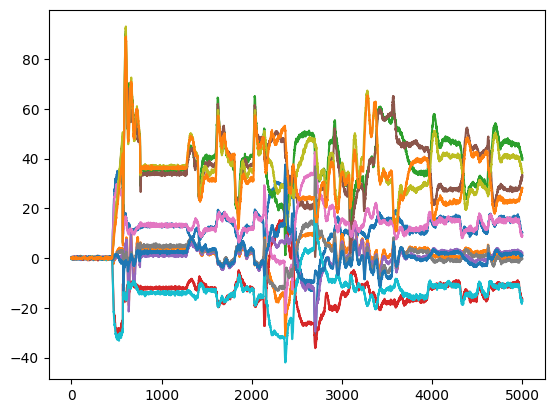

In [47]:
import matplotlib.pyplot as plt
plt.plot(taus)

In [48]:
import pickle
with open('b1_rotating.pkl', 'wb') as f:
    pickle.dump(
        {
            'q':q,
            'dq':dq, 
            'tau':tau, 
            'stamp':stamp
        }
        ,f
    )